# Explicabilidade v2: M4 Monthly (protocolo único v2)

**O que é explicado.** Para cada uma das 30 séries (sorteio SEED+1 sobre a amostra da base, regra do NB09), RF, GB e SVR são treinados na **última janela** (treino = série[:-H]), limpo ou com ruído σ=30% do desvio do próprio treino. SHAP e LIME explicam **os mesmos 30 pontos** desse modelo: as 29 linhas de treino mais recentes e o **ponto de previsão** (features do 1º passo da previsão, calculadas a partir do histórico que o modelo vê).

### Diferenças em relação ao NB09
| Item | NB09 | v2 |
|---|---|---|
| Pontos explicados | SHAP: todas as linhas de treino (árvores) ou 30 sorteadas (SVR); LIME: só a última linha de treino | os mesmos 30 pontos para SHAP e LIME |
| Features | 17, com lag_season = lag_12 duplicado | 15, sem duplicata; lag_12 é o lag sazonal |
| LIME | associação por substring (bug) | por índice (`as_map()[1]`) |
| SHAP do SVR | sem semente, nsamples=50, escala normalizada | semente fixa, nsamples = 2p + 2048, escala original |
| Agregação | média simples de importâncias em escala original | normalização por série (soma 1) antes da média |
| Ruído da estabilidade | gerador sequencial sobre as séries | semente por série, σ do próprio treino |
| Incerteza | nenhuma | IC de 95% por bootstrap sobre as séries (2000 reamostragens) |

Resultados oficiais: LIME com 200 amostras. Sensibilidade (1000 e 5000) e análise com lag_24 são **suplementares**.

In [1]:
import sys, json, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

_root = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in (_root, *_root.parents) if (c / 'src' / 'pipeline_v2.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src import pipeline_v2 as pv

BASE = 'm4'
DIR = PROJECT_ROOT / 'results' / 'v2' / BASE / 'xai'
FN, FN24 = pv.feature_names(), pv.feature_names(com_lag24=True)
MOD = pv.MODELOS_XAI
MET = ['shap', 'lime']
pd.set_option('display.width', 250)

def ler(nome):
    p = DIR / f'xai_{BASE}_{nome}_pontos.csv'
    return pd.read_csv(p) if p.exists() else None

pts = {c: ler(c) for c in ['limpo', 'ruido30']}
sens = {(n, c): ler(f'{c}_lime{n}') for n in (1000, 5000) for c in ['limpo', 'ruido30']}
lag24 = {c: ler(f'{c}_lag24') for c in ['limpo', 'ruido30']}
for c, d in pts.items():
    print(c, d.groupby(['modelo', 'metodo']).serie.nunique().unstack().to_dict(), '| pontos por série:',
          d.groupby(['serie', 'modelo', 'metodo']).size().unique())

def imp_serie(d, nomes=FN, tipo=None):
    """Importância por série (média de |atribuição| nos pontos) normalizada para somar 1."""
    i = pv.importancia_por_serie(d, nomes, tipo)
    return pv.normalizar_por_serie(i, nomes)

imp = pd.concat([imp_serie(d) for d in pts.values()], ignore_index=True)
imp_prev = pd.concat([imp_serie(d, tipo='previsao') for d in pts.values()], ignore_index=True)

limpo {'lime': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}, 'shap': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}} | pontos por série: [30]
ruido30 {'lime': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}, 'shap': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}} | pontos por série: [30]


## 1. Importância global (normalizada por série) e top-10

In [2]:
def glob(i, modelo, metodo, cond, nomes=FN):
    return i[(i.modelo == modelo) & (i.metodo == metodo) & (i.condicao == cond)][nomes].mean()

linhas = []
for cond in ['limpo', 'ruido30']:
    for m in MOD:
        for met in MET:
            g = glob(imp, m, met, cond)
            linhas.append({'condicao': cond, 'modelo': m, 'metodo': met,
                           'top10': ', '.join(g.sort_values(ascending=False).index[:10]),
                           'pos_lag_12': int(g.rank(ascending=False, method='min')['lag_12']),
                           'lag_1': g['lag_1'], 'roll_mean_3': g['roll_mean_3'], 'roll_mean_6': g['roll_mean_6'],
                           'lag_12': g['lag_12']})
top = pd.DataFrame(linhas)
top.to_csv(DIR / f'xai_{BASE}_top10_global.csv', index=False)
for cond in ['limpo', 'ruido30']:
    print(f'=== {cond} ===')
    for _, r in top[top.condicao == cond].iterrows():
        print(f"{r.modelo:<17} {r.metodo:<5} lag_12 em {r.pos_lag_12:>2}º | {r.top10}")
    print()

=== limpo ===
RandomForest      shap  lag_12 em  3º | lag_1, roll_mean_3, lag_12, roll_mean_6, lag_3, lag_2, lag_5, lag_8, lag_4, lag_11
RandomForest      lime  lag_12 em  3º | lag_1, roll_mean_3, lag_12, roll_mean_6, lag_3, lag_2, lag_11, lag_5, lag_8, lag_4
GradientBoosting  shap  lag_12 em  3º | lag_1, roll_mean_3, lag_12, roll_mean_6, lag_3, lag_2, lag_4, lag_8, lag_11, lag_10
GradientBoosting  lime  lag_12 em  3º | lag_1, roll_mean_3, lag_12, roll_mean_6, lag_3, lag_11, lag_2, lag_4, lag_10, lag_7
SVR               shap  lag_12 em  5º | lag_1, roll_mean_3, lag_2, roll_mean_6, lag_12, lag_3, lag_4, lag_5, lag_10, lag_9
SVR               lime  lag_12 em  4º | lag_1, roll_mean_3, lag_2, lag_12, roll_mean_6, lag_3, lag_10, lag_4, lag_5, lag_9

=== ruido30 ===
RandomForest      shap  lag_12 em  4º | roll_mean_3, roll_mean_6, lag_1, lag_12, lag_2, lag_9, lag_8, lag_3, lag_6, lag_7
RandomForest      lime  lag_12 em  4º | roll_mean_3, roll_mean_6, lag_1, lag_12, lag_2, lag_9, lag_3, lag_7

## 2. Estabilidade entre limpo e ruído σ=30% (por série), com IC por bootstrap
Spearman entre os vetores de importância da mesma série (limpo x ruído) e Jaccard dos conjuntos top-3 e top-5. Estatística: média entre as 30 séries; IC 95% por bootstrap (2000). A mediana também é reportada.

In [3]:
def tab_estab(i, nomes=FN):
    linhas = []
    for met in MET:
        sub = i[i.metodo == met]
        e = pv.estabilidade(sub[sub.condicao == 'limpo'], sub[sub.condicao == 'ruido30'], nomes)
        for m in MOD:
            em = e[e.modelo == m]
            lin = {'modelo': m, 'metodo': met, 'n_series': len(em)}
            for col in ['spearman', 'jaccard_top3', 'jaccard_top5']:
                est, lo, hi = pv.bootstrap_ic(em[col].values)
                lin[col] = f'{est:.3f} [{lo:.3f}; {hi:.3f}]'
                lin[f'{col}_mediana'] = round(float(em[col].median()), 3)
            linhas.append(lin)
    return pd.DataFrame(linhas)

estab = tab_estab(imp)
estab.to_csv(DIR / f'xai_{BASE}_estabilidade.csv', index=False)
print(estab.to_string(index=False))

          modelo metodo  n_series             spearman  spearman_mediana         jaccard_top3  jaccard_top3_mediana         jaccard_top5  jaccard_top5_mediana
    RandomForest   shap        30 0.561 [0.480; 0.632]             0.584 0.617 [0.487; 0.737]                   0.5 0.568 [0.502; 0.634]                 0.667
GradientBoosting   shap        30 0.436 [0.372; 0.500]             0.405 0.457 [0.357; 0.553]                   0.5 0.451 [0.378; 0.531]                 0.429
             SVR   shap        30 0.616 [0.528; 0.695]             0.630 0.527 [0.427; 0.630]                   0.5 0.536 [0.457; 0.622]                 0.429
    RandomForest   lime        30 0.485 [0.399; 0.566]             0.514 0.467 [0.363; 0.587]                   0.5 0.462 [0.396; 0.537]                 0.429
GradientBoosting   lime        30 0.442 [0.379; 0.510]             0.446 0.430 [0.330; 0.543]                   0.5 0.422 [0.363; 0.490]                 0.429
             SVR   lime        30 0.572 [0.483

## 3. Concordância SHAP x LIME
(a) Entre as importâncias globais (normalizadas por série): Pearson (normalização pelo máximo, como na Fig. 20) e Spearman. (b) Por série: Spearman entre o vetor SHAP e o vetor LIME da mesma série, média com IC.

In [4]:
def tab_conc(i, nomes=FN):
    linhas = []
    for cond in ['limpo', 'ruido30']:
        for m in MOD:
            s, l = glob(i, m, 'shap', cond, nomes), glob(i, m, 'lime', cond, nomes)
            pear = np.corrcoef((s / s.max()).values, (l / l.max()).values)[0, 1]
            spe = spearmanr(s.values, l.values)[0]
            a = i[(i.modelo == m) & (i.condicao == cond)]
            j = a[a.metodo == 'shap'].merge(a[a.metodo == 'lime'], on='serie', suffixes=('_s', '_l'))
            por_serie = [spearmanr(r[[f'{n}_s' for n in nomes]].astype(float), r[[f'{n}_l' for n in nomes]].astype(float))[0]
                         for _, r in j.iterrows()]
            est, lo, hi = pv.bootstrap_ic(por_serie)
            linhas.append({'condicao': cond, 'modelo': m, 'pearson_global': round(pear, 3), 'spearman_global': round(spe, 3),
                           'spearman_por_serie': f'{est:.3f} [{lo:.3f}; {hi:.3f}]'})
    return pd.DataFrame(linhas)

conc = tab_conc(imp)
conc.to_csv(DIR / f'xai_{BASE}_concordancia_shap_lime.csv', index=False)
print(conc.to_string(index=False))

condicao           modelo  pearson_global  spearman_global   spearman_por_serie
   limpo     RandomForest           0.997            0.954 0.653 [0.553; 0.746]
   limpo GradientBoosting           0.996            0.907 0.702 [0.621; 0.780]
   limpo              SVR           0.993            0.946 0.824 [0.748; 0.881]
 ruido30     RandomForest           0.998            0.979 0.732 [0.674; 0.786]
 ruido30 GradientBoosting           0.993            0.964 0.768 [0.719; 0.816]
 ruido30              SVR           0.993            0.986 0.795 [0.733; 0.852]


## 4. Posição do lag_12 (lag sazonal): global e por série

In [5]:
def pos_lag(i, feat='lag_12', nomes=FN):
    linhas = []
    for cond in ['limpo', 'ruido30']:
        for m in MOD:
            for met in MET:
                sub = i[(i.modelo == m) & (i.metodo == met) & (i.condicao == cond)]
                r = sub[nomes].rank(axis=1, ascending=False, method='min')[feat]
                g = glob(i, m, met, cond, nomes)
                linhas.append({'condicao': cond, 'modelo': m, 'metodo': met,
                               'pos_global': int(g.rank(ascending=False, method='min')[feat]),
                               'pos_mediana_por_serie': float(r.median()),
                               '% séries no top-3': round(100 * (r <= 3).mean(), 1),
                               'importância normalizada': round(g[feat], 4)})
    return pd.DataFrame(linhas)

lag12 = pos_lag(imp)
lag12.to_csv(DIR / f'xai_{BASE}_posicao_lag12.csv', index=False)
print(lag12.to_string(index=False))

condicao           modelo metodo  pos_global  pos_mediana_por_serie  % séries no top-3  importância normalizada
   limpo     RandomForest   shap           3                    7.5               16.7                   0.0945
   limpo     RandomForest   lime           3                    8.5               16.7                   0.0804
   limpo GradientBoosting   shap           3                    7.0               26.7                   0.1031
   limpo GradientBoosting   lime           3                    7.5               26.7                   0.0875
   limpo              SVR   shap           5                    8.5               20.0                   0.0823
   limpo              SVR   lime           4                    8.0               30.0                   0.0771
 ruido30     RandomForest   shap           4                    8.5               20.0                   0.0706
 ruido30     RandomForest   lime           4                    9.0               23.3                  

## 5. Redistribuição de importância sob ruído (equivalente à Fig. 22)
Importância normalizada (fração da soma por série) de lag_1, roll_mean_3 e roll_mean_6, limpo x ruído, com IC 95% por bootstrap sobre as séries.

          modelo metodo     feature  limpo       limpo_ic  ruido30     ruido30_ic       Δ (ruído − limpo)  IC inclui zero
    RandomForest   shap       lag_1  0.361 [0.263; 0.456]    0.173 [0.121; 0.232] -0.188 [-0.266; -0.110]           False
    RandomForest   shap roll_mean_3  0.123 [0.092; 0.162]    0.219 [0.170; 0.269] +0.096 [+0.042; +0.153]           False
    RandomForest   shap roll_mean_6  0.090 [0.065; 0.120]    0.192 [0.143; 0.248] +0.102 [+0.057; +0.152]           False
    RandomForest   shap      lag_12  0.094 [0.034; 0.174]    0.071 [0.029; 0.122] -0.024 [-0.071; +0.019]            True
    RandomForest   lime       lag_1  0.254 [0.204; 0.306]    0.142 [0.105; 0.183] -0.112 [-0.150; -0.075]           False
    RandomForest   lime roll_mean_3  0.101 [0.079; 0.128]    0.161 [0.132; 0.187] +0.060 [+0.026; +0.091]           False
    RandomForest   lime roll_mean_6  0.079 [0.062; 0.100]    0.147 [0.114; 0.184] +0.068 [+0.042; +0.093]           False
    RandomForest   lime 

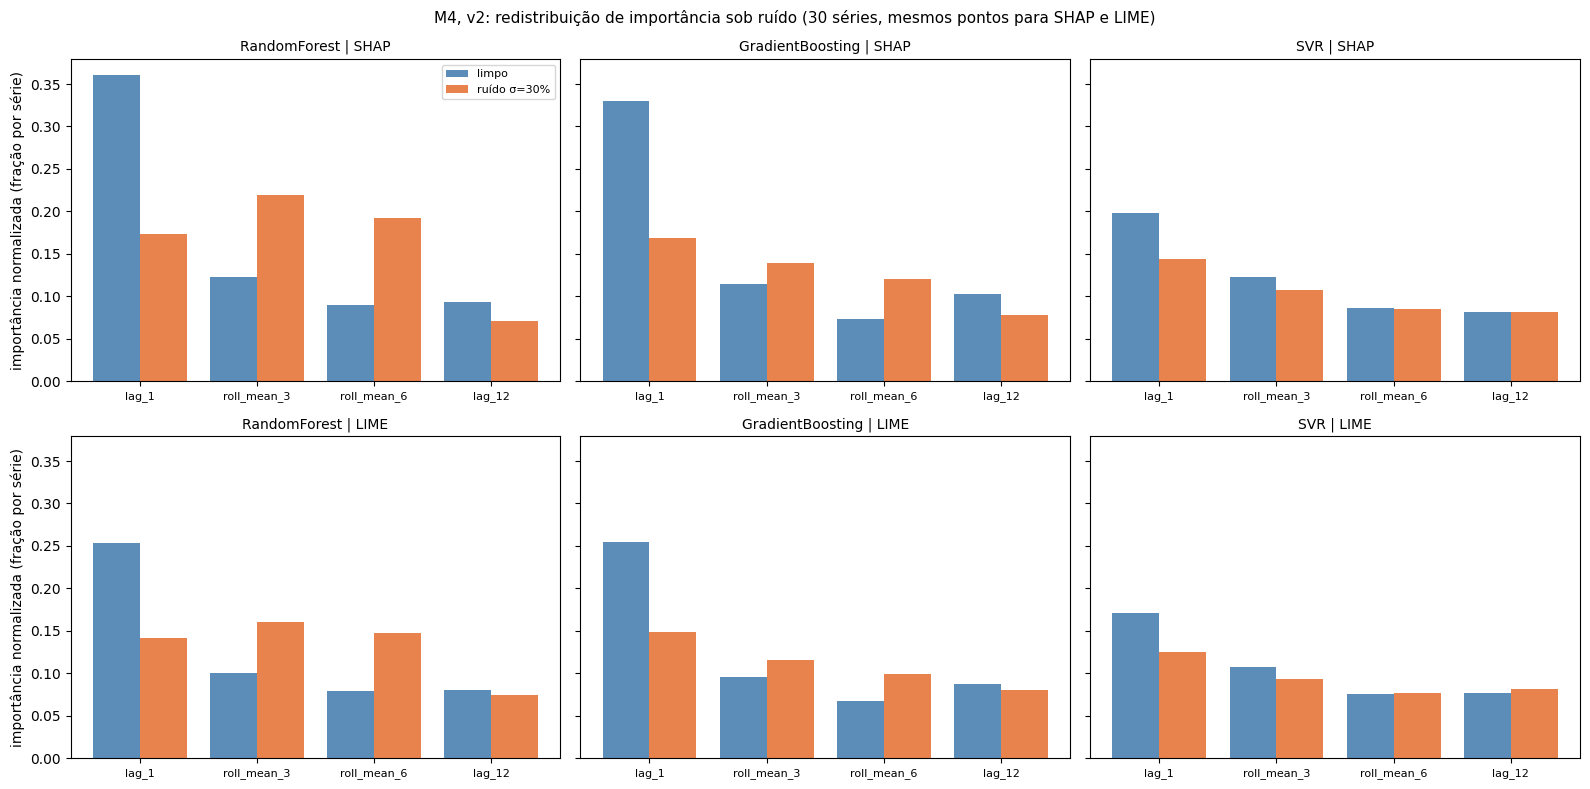

In [6]:
FEATS = ['lag_1', 'roll_mean_3', 'roll_mean_6', 'lag_12']
linhas = []
for m in MOD:
    for met in MET:
        for f in FEATS:
            lin = {'modelo': m, 'metodo': met, 'feature': f}
            for cond in ['limpo', 'ruido30']:
                v = imp[(imp.modelo == m) & (imp.metodo == met) & (imp.condicao == cond)][f].values
                est, lo, hi = pv.bootstrap_ic(v)
                lin[cond], lin[f'{cond}_ic'] = round(est, 3), f'[{lo:.3f}; {hi:.3f}]'
            a = imp[(imp.modelo == m) & (imp.metodo == met)]
            j = a[a.condicao == 'limpo'][['serie', f]].merge(a[a.condicao == 'ruido30'][['serie', f]], on='serie')
            est, lo, hi = pv.bootstrap_ic((j[f'{f}_y'] - j[f'{f}_x']).values)
            lin['Δ (ruído − limpo)'] = f'{est:+.3f} [{lo:+.3f}; {hi:+.3f}]'
            lin['IC inclui zero'] = lo <= 0 <= hi
            linhas.append(lin)
redis = pd.DataFrame(linhas)
redis.to_csv(DIR / f'xai_{BASE}_redistribuicao_ruido.csv', index=False)
print(redis.to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for r_, met in enumerate(MET):
    for c_, m in enumerate(MOD):
        ax = axes[r_, c_]; sub = redis[(redis.modelo == m) & (redis.metodo == met)]
        x = np.arange(len(FEATS))
        ax.bar(x - 0.2, sub['limpo'], 0.4, label='limpo', color='#5B8DB8')
        ax.bar(x + 0.2, sub['ruido30'], 0.4, label='ruído σ=30%', color='#E8834E')
        ax.set_xticks(x); ax.set_xticklabels(FEATS, fontsize=8); ax.set_title(f'{m} | {met.upper()}', fontsize=10)
        if c_ == 0: ax.set_ylabel('importância normalizada (fração por série)')
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'{BASE.upper()}, v2: redistribuição de importância sob ruído (30 séries, mesmos pontos para SHAP e LIME)', fontsize=11)
plt.tight_layout(); plt.savefig(DIR / f'fig_v2_{BASE}_redistribuicao_ruido.png', dpi=150, bbox_inches='tight'); plt.show()

### 5.1 Só o ponto de previsão (suplementar)
As mesmas métricas usando apenas o ponto de previsão (1 ponto por série), em vez dos 30 pontos.

In [7]:
print('Estabilidade (só o ponto de previsão):'); print(tab_estab(imp_prev).to_string(index=False)); print()
print('Concordância SHAP x LIME (só o ponto de previsão):'); print(tab_conc(imp_prev).to_string(index=False))

Estabilidade (só o ponto de previsão):
          modelo metodo  n_series             spearman  spearman_mediana         jaccard_top3  jaccard_top3_mediana         jaccard_top5  jaccard_top5_mediana
    RandomForest   shap        30 0.460 [0.346; 0.557]             0.537 0.470 [0.357; 0.587]                   0.5 0.488 [0.394; 0.583]                 0.429
GradientBoosting   shap        30 0.405 [0.323; 0.477]             0.462 0.363 [0.283; 0.447]                   0.5 0.396 [0.328; 0.475]                 0.429
             SVR   shap        30 0.515 [0.417; 0.609]             0.552 0.413 [0.313; 0.523]                   0.5 0.463 [0.381; 0.557]                 0.429
    RandomForest   lime        30 0.449 [0.326; 0.558]             0.568 0.410 [0.320; 0.510]                   0.5 0.445 [0.375; 0.516]                 0.429
GradientBoosting   lime        30 0.336 [0.230; 0.441]             0.379 0.380 [0.283; 0.487]                   0.5 0.376 [0.313; 0.451]                 0.429
       

## 6. Sensibilidade do LIME (1000 e 5000 amostras), separada do resultado oficial
O SHAP é o mesmo do resultado oficial; só o LIME muda.

In [8]:
linhas = []
for n in (200, 1000, 5000):
    if n == 200:
        lime_d = {c: pts[c][pts[c].metodo == 'lime'] for c in pts}
    else:
        if any(sens[(n, c)] is None for c in pts):
            print(f'sem cache para {n} amostras'); continue
        lime_d = {c: sens[(n, c)] for c in pts}
    comb = pd.concat([imp_serie(pts[c][pts[c].metodo == 'shap']) for c in pts] +
                     [imp_serie(lime_d[c]) for c in pts], ignore_index=True)
    cc = tab_conc(comb); pl = pos_lag(comb); es = tab_estab(comb)
    for m in MOD:
        for cond in ['limpo', 'ruido30']:
            g = glob(comb, m, 'lime', cond)
            linhas.append({'lime_samples': n, 'modelo': m, 'condicao': cond,
                           'pearson_shap_lime': cc[(cc.modelo == m) & (cc.condicao == cond)].pearson_global.iloc[0],
                           'spearman_shap_lime': cc[(cc.modelo == m) & (cc.condicao == cond)].spearman_global.iloc[0],
                           'pos_lag_12_lime': pl[(pl.modelo == m) & (pl.condicao == cond) & (pl.metodo == 'lime')].pos_global.iloc[0],
                           'estab_spearman_lime': es[(es.modelo == m) & (es.metodo == 'lime')].spearman.iloc[0] if cond == 'limpo' else '',
                           'top10_lime': ', '.join(g.sort_values(ascending=False).index[:10])})
sens_tab = pd.DataFrame(linhas)
sens_tab.to_csv(DIR / f'xai_{BASE}_sensibilidade_lime.csv', index=False)
print(sens_tab.drop(columns='top10_lime').to_string(index=False)); print()
for _, r in sens_tab[sens_tab.condicao == 'limpo'].iterrows():
    print(f'{r.lime_samples:>5} {r.modelo:<17} {r.top10_lime}')

 lime_samples           modelo condicao  pearson_shap_lime  spearman_shap_lime  pos_lag_12_lime  estab_spearman_lime
          200     RandomForest    limpo              0.997               0.954                3 0.485 [0.399; 0.566]
          200     RandomForest  ruido30              0.998               0.979                4                     
          200 GradientBoosting    limpo              0.996               0.907                3 0.442 [0.379; 0.510]
          200 GradientBoosting  ruido30              0.993               0.964                4                     
          200              SVR    limpo              0.993               0.946                4 0.572 [0.483; 0.663]
          200              SVR  ruido30              0.993               0.986                4                     
         1000     RandomForest    limpo              0.998               0.925                3 0.527 [0.453; 0.595]
         1000     RandomForest  ruido30              0.998      

## 7. Análise SUPLEMENTAR (não oficial): última janela com lag_24 incluído
16 features (as 15 oficiais + lag_24). Os números não substituem os oficiais.

In [9]:
if all(lag24[c] is not None for c in lag24):
    imp24 = pd.concat([imp_serie(lag24[c], FN24) for c in lag24], ignore_index=True)
    p12, p24 = pos_lag(imp24, 'lag_12', FN24), pos_lag(imp24, 'lag_24', FN24)
    sup = p12[['condicao', 'modelo', 'metodo', 'pos_global', '% séries no top-3']].rename(
        columns={'pos_global': 'pos lag_12', '% séries no top-3': 'lag_12 top-3 (%)'})
    sup['pos lag_24'] = p24['pos_global'].values
    sup['lag_24 top-3 (%)'] = p24['% séries no top-3'].values
    sup['lag_12 + lag_24 (fração)'] = (p12['importância normalizada'] + p24['importância normalizada']).round(3).values
    print(sup.to_string(index=False))
    print('\nConcordância SHAP x LIME com lag_24:'); print(tab_conc(imp24, FN24).to_string(index=False))
    print('\nEstabilidade com lag_24:'); print(tab_estab(imp24, FN24).to_string(index=False))
    sup.to_csv(DIR / f'xai_{BASE}_suplementar_lag24.csv', index=False)
else:
    print('caches com lag_24 ausentes')

condicao           modelo metodo  pos lag_12  lag_12 top-3 (%)  pos lag_24  lag_24 top-3 (%)  lag_12 + lag_24 (fração)
   limpo     RandomForest   shap           6              16.7           5              20.0                     0.125
   limpo     RandomForest   lime           4              23.3           5              16.7                     0.130
   limpo GradientBoosting   shap           3              30.0           5              23.3                     0.147
   limpo GradientBoosting   lime           3              30.0           5              26.7                     0.142
   limpo              SVR   shap           5              20.0           7              23.3                     0.137
   limpo              SVR   lime           6              23.3           7              13.3                     0.127
 ruido30     RandomForest   shap           4              16.7           7              10.0                     0.108
 ruido30     RandomForest   lime           4    

## 8. Comparação com a dissertação (Fig. 20, Fig. 22 e Spearman de estabilidade)
Valores antigos: dissertação (com o bug do LIME e a feature duplicada) e NB09 corrigido em out/2026 (LIME por índice, mas ainda com os demais problemas do NB09).

In [10]:
ANT = pd.DataFrame({
    'Pearson SHAP×LIME, dissertação (Fig. 20)': {'RandomForest': 0.959, 'GradientBoosting': 0.952, 'SVR': 0.908},
    'Pearson, NB09 com LIME corrigido': {'RandomForest': 0.992, 'GradientBoosting': 0.994, 'SVR': 0.980},
    'Spearman estabilidade SHAP (mediana), dissertação': {'RandomForest': 0.572, 'GradientBoosting': 0.344, 'SVR': 0.520},
})
c_l = conc[conc.condicao == 'limpo'].set_index('modelo')
e_s = estab[estab.metodo == 'shap'].set_index('modelo')
ANT['Pearson v2 (limpo)'] = c_l['pearson_global']
ANT['Spearman SHAP×LIME v2 (limpo)'] = c_l['spearman_global']
ANT['Spearman estabilidade SHAP v2 (mediana)'] = e_s['spearman_mediana']
ANT['Spearman estabilidade SHAP v2 (média [IC])'] = e_s['spearman']
print(ANT.T.to_string()); print()

# Fig. 22: valores antigos (medianas brutas de |SHAP|) e a mesma informação normalizada
st = pd.read_csv(PROJECT_ROOT / 'results' / 'explicabilidade' / 'shap_estabilidade_adversa.csv')
FN_ANT = [c.replace('shap_clean_', '') for c in st.columns if c.startswith('shap_clean_')]
linhas = []
for m in MOD:
    s = st[st.modelo == m]
    cl = s[[f'shap_clean_{f}' for f in FN_ANT]].values; pe = s[[f'shap_pert_{f}' for f in FN_ANT]].values
    cln, pen = cl / cl.sum(1, keepdims=True), pe / pe.sum(1, keepdims=True)
    for f in ['lag_1', 'roll_mean_6']:
        k = FN_ANT.index(f)
        v2 = redis[(redis.modelo == m) & (redis.metodo == 'shap') & (redis.feature == f)].iloc[0]
        linhas.append({'modelo': m, 'feature': f,
                       'antigo bruto (mediana) limpo→ruído': f'{np.median(cl[:, k]):.3f} → {np.median(pe[:, k]):.3f}',
                       'antigo normalizado (média) limpo→ruído': f'{cln[:, k].mean():.3f} → {pen[:, k].mean():.3f}',
                       'v2 normalizado (média) limpo→ruído': f"{v2['limpo']:.3f} → {v2['ruido30']:.3f}",
                       'v2 Δ [IC 95%]': v2['Δ (ruído − limpo)']})
fig22 = pd.DataFrame(linhas)
print(fig22.to_string(index=False))
fig22.to_csv(DIR / 'xai_m4_comparacao_fig22.csv', index=False)
ANT.to_csv(DIR / 'xai_m4_comparacao_dissertacao.csv')

                                                           RandomForest      GradientBoosting                   SVR
Pearson SHAP×LIME, dissertação (Fig. 20)                          0.959                 0.952                 0.908
Pearson, NB09 com LIME corrigido                                  0.992                 0.994                  0.98
Spearman estabilidade SHAP (mediana), dissertação                 0.572                 0.344                  0.52
Pearson v2 (limpo)                                                0.997                 0.996                 0.993
Spearman SHAP×LIME v2 (limpo)                                     0.954                 0.907                 0.946
Spearman estabilidade SHAP v2 (mediana)                           0.584                 0.405                  0.63
Spearman estabilidade SHAP v2 (média [IC])         0.561 [0.480; 0.632]  0.436 [0.372; 0.500]  0.616 [0.528; 0.695]

          modelo     feature antigo bruto (mediana) limpo→ruído antigo 